In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mlflow
from scipy.stats import gaussian_kde, norm

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split

## Paso 1: Cargando y describiendo el dataset

Estaré usando en esta ocasión *Bank Marketing* (UCI Dataset ID = 222). Un dataset que registra los resultados de una campaña de marketing hecha por un banco de Portugal. El objetivo es predecir si el cliente adquirirá el depósito a plazo o no. Es un problema de clasificación binaria.

In [2]:
# 1 - load and describe dataset
bank = fetch_ucirepo(id=222)
X = bank.data.features.copy()
y = (bank.data.targets.squeeze() == "yes").astype(int)


In [3]:
X.columns.tolist()

['age',
 'job',
 'marital',
 'education',
 'default',
 'balance',
 'housing',
 'loan',
 'contact',
 'day_of_week',
 'month',
 'duration',
 'campaign',
 'pdays',
 'previous',
 'poutcome']

**Descripción de los datos:**

* age
* job: type of job (categorical: 'admin.','blue-collar','entrepreneur','housemaid','management','retired','self-employed','services','student','technician','unemployed')
* marital: marital status (categorical: 'divorced','married','single'; note: 'divorced' means divorced or widowed)
* education: (categorical: 'primary', 'secondary', 'tertiary')
* default: has credit in default? (yes/no)
* balance: average yearly account balance in euros
* housing: has housing loan? (yes/no)
* loan: has a personal loan? (yes/no)
* contact: contact communication type (categorical: 'cellular','telephone')
* day_of_week: last contact day of the week
* month: last contact month of year (categorical: 'jan', 'feb', 'mar', ..., 'nov', 'dec')
* duration: Duration of the last contact in seconds
* campaign: Number of contact attempts made during the campaign
* pdays: number of days that passed by after the client was last contacted from a previous campaign (numeric; -1 means client was not previously contacted)
* previous: number of contacts performed before this campaign and for this client
* poutcome: outcome of the previous marketing campaign (categorical: 'failure','other','success')
* y: target: has the client subscribed a term deposit?

In [3]:
# create dataframe
df = X.assign(target=y)

**NOTA: day_of_week es incorrecto, debería ser day_of_month** actualizando ahora antes de hacer EDA.

In [4]:
df = df.rename(columns={"day_of_week": "day_of_month"})

Declarando variables numéricas y categóricas (list)

In [6]:
num_cols = df.select_dtypes("number").columns.drop("target").tolist()
cat_cols = df.select_dtypes(exclude="number").columns.tolist()

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   age           45211 non-null  int64
 1   job           44923 non-null  str  
 2   marital       45211 non-null  str  
 3   education     43354 non-null  str  
 4   default       45211 non-null  str  
 5   balance       45211 non-null  int64
 6   housing       45211 non-null  str  
 7   loan          45211 non-null  str  
 8   contact       32191 non-null  str  
 9   day_of_month  45211 non-null  int64
 10  month         45211 non-null  str  
 11  duration      45211 non-null  int64
 12  campaign      45211 non-null  int64
 13  pdays         45211 non-null  int64
 14  previous      45211 non-null  int64
 15  poutcome      8252 non-null   str  
 16  target        45211 non-null  int64
dtypes: int64(8), str(9)
memory usage: 7.7 MB


De acuerdo a info, tenemos 7 atributos numéricos y 9 de texto (str)

In [8]:
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
day_of_month,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0


In [9]:
df[cat_cols].nunique()

job          11
marital       3
education     3
default       2
housing       2
loan          2
contact       2
month        12
poutcome      3
dtype: int64

## Paso 2: Realizando un análisis exploratorio (EDA)

La idea es hacer un análisis inicial del dataset para entender distribuciones, detectar *outliers*, valores faltantes, y descubrir algunos patrones.

In [10]:
df.shape

(45211, 17)

### 2.1 Análisis de target

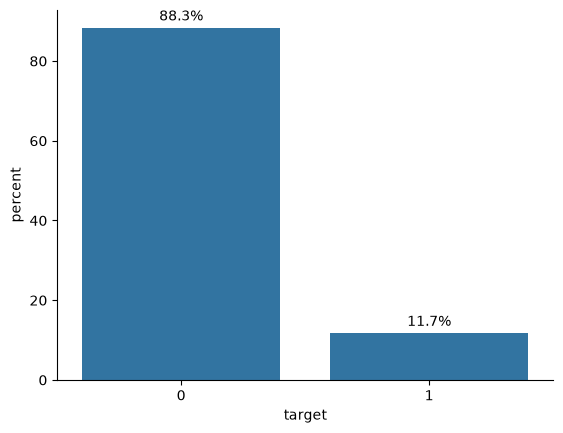

In [11]:
ax = sns.countplot(x='target', data=df, stat='percent')
ax.bar_label(ax.containers[0], fmt='%.1f%%', padding=3)
sns.despine()

In [12]:
df['target'].value_counts(normalize=True)

target
0    0.883015
1    0.116985
Name: proportion, dtype: float64

**Clases desbalanceadas**

El desbalanceamiento de `target` 11.7% para la clase positiva. Si un modelo siempre predice la clase mayoritaria, qué accuracy tendría (88.3%).
Por lo que se tendrá que aplicar una técnica de estratificación y/o sobremuestreo.

Además la métrica de accuracy no nos ayudará aquí, por lo que debemos explorar otras: precisión, recall y/o F1_score.

### 2.2 Distribuciones numéricas

array([[<Axes: title={'center': 'age'}>,
        <Axes: title={'center': 'balance'}>,
        <Axes: title={'center': 'day_of_month'}>],
       [<Axes: title={'center': 'duration'}>,
        <Axes: title={'center': 'campaign'}>,
        <Axes: title={'center': 'pdays'}>],
       [<Axes: title={'center': 'previous'}>, <Axes: >, <Axes: >]],
      dtype=object)

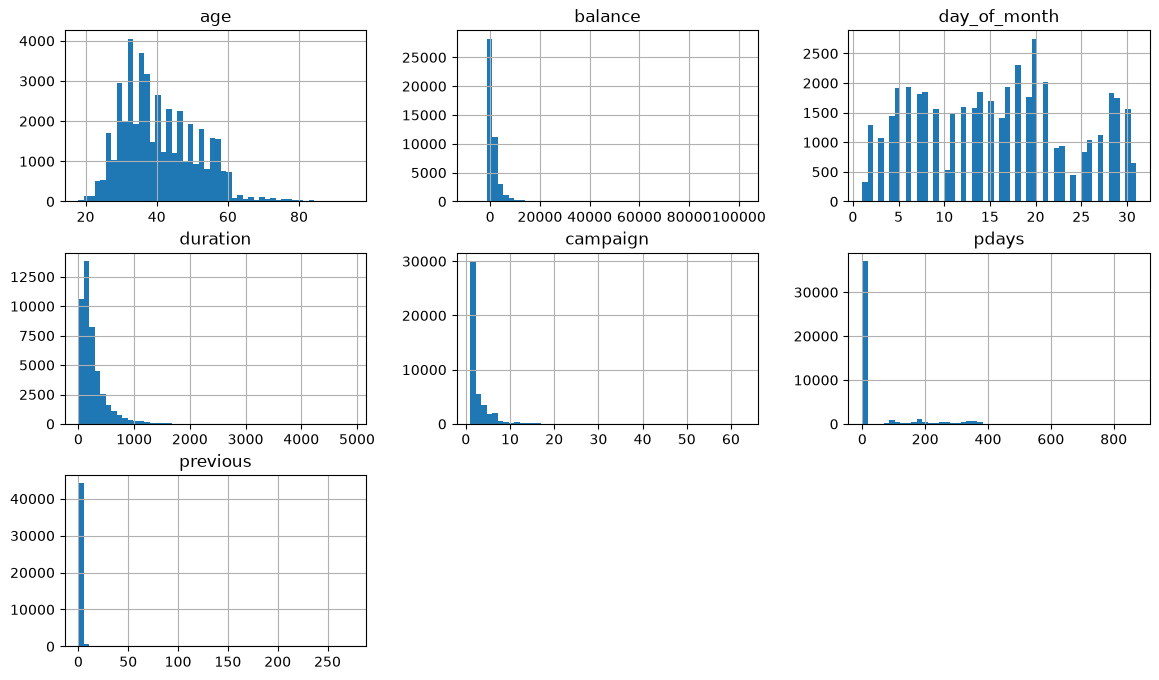

In [13]:
df[num_cols].hist(bins=50, figsize=(14, 8))

En los gráficos numéricos podemos ver que existen varias variables con sesgo positivo (long-tailed), entre ellas `balance`, `duration`, `campaign` y `previous`. Por lo que le debemos aplicar transformación logarítmica. 

Además, `balance` tiene valores negativos, se investigará que otro tipo de transformación debería llevarse para no afectar al modelo.

Finalmente, haremos StandardScaler a todas las numéricas.

### 2.3 `pdays` y outliers

Los siguientes análisis demostrarán la relación que hay con `pdays`. La variable que indica el número de días que pasaron desde el último contacto hacia el cliente.

In [14]:
(df["pdays"] == -1).mean()

np.float64(0.8173674548229414)

In [15]:
df.loc[df["pdays"] != -1, "pdays"].describe()

count    8257.000000
mean      224.577692
std       115.344035
min         1.000000
25%       133.000000
50%       194.000000
75%       327.000000
max       871.000000
Name: pdays, dtype: float64

In [16]:
df.nlargest(5, "previous")[["previous", "pdays", "poutcome"]]

,previous,pdays,poutcome
29182,275,262,other
38326,58,353,other
44089,55,776,failure
28886,51,256,failure
44822,41,778,other


In [17]:
df["campaign"].value_counts().sort_index().tail(10)

campaign
39    1
41    2
43    3
44    1
46    1
50    2
51    1
55    1
58    1
63    1
Name: count, dtype: int64

De acuerdo a los datos, **81.7%** es el promedio de registros con valor de -1, indicando que el cliente no había sido contactado antes.

Además, `previous` y `campaign` tienen valores extremos, por ejemplo `previous` = 275.

Se añadirá otra categoría: `previously_contacted = (pdays != -1)` y se hará *drop* de `pdays`.

### 2.4 **Comparando categorías con el target**

,rate,n
job,,
student,0.286780,938
retired,0.227915,2264
unemployed,0.155027,1303
management,0.137556,9458
admin.,0.122027,5171
self-employed,0.118429,1579
NaN,0.118056,288
technician,0.110570,7597
services,0.088830,4154


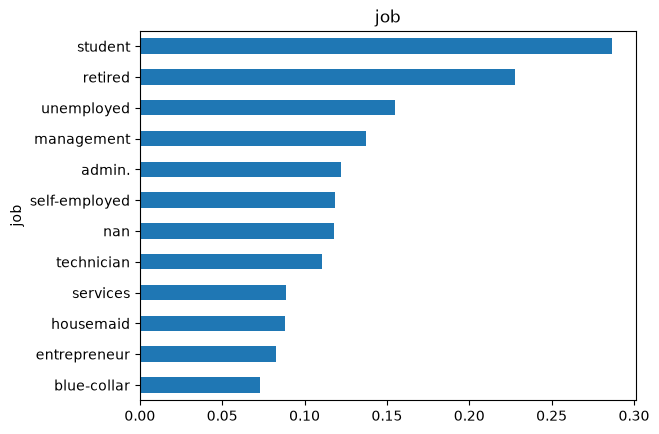

,rate,n
marital,,
single,0.149492,12790
divorced,0.119455,5207
married,0.101235,27214


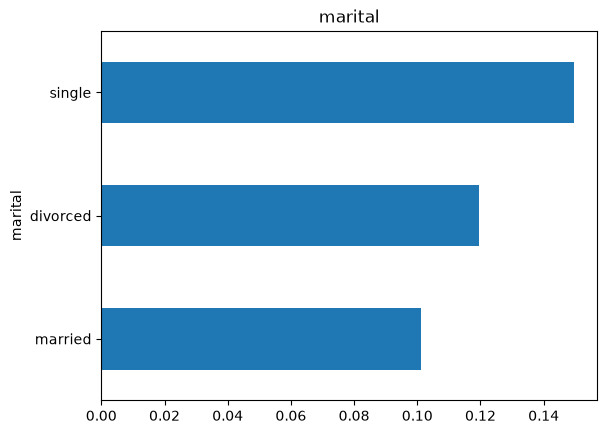

,rate,n
education,,
tertiary,0.150064,13301
NaN,0.135703,1857
secondary,0.105594,23202
primary,0.086265,6851


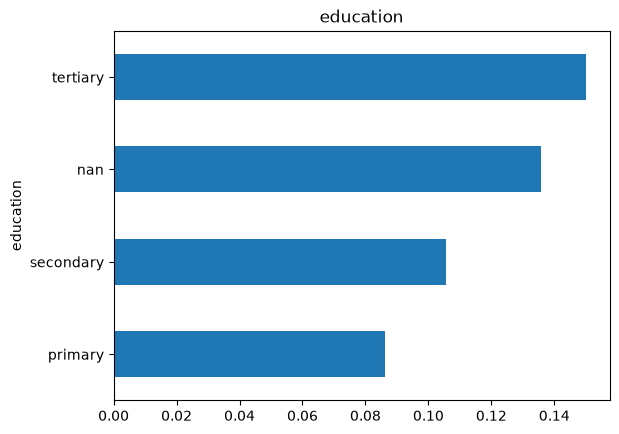

,rate,n
default,,
no,0.117961,44396
yes,0.063804,815


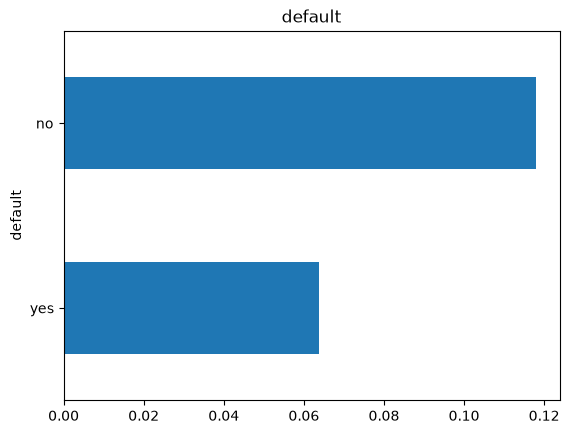

,rate,n
housing,,
no,0.167024,20081
yes,0.077000,25130


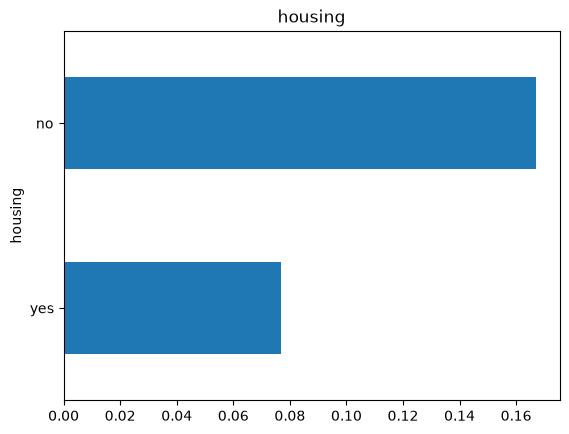

,rate,n
loan,,
no,0.126557,37967
yes,0.066814,7244


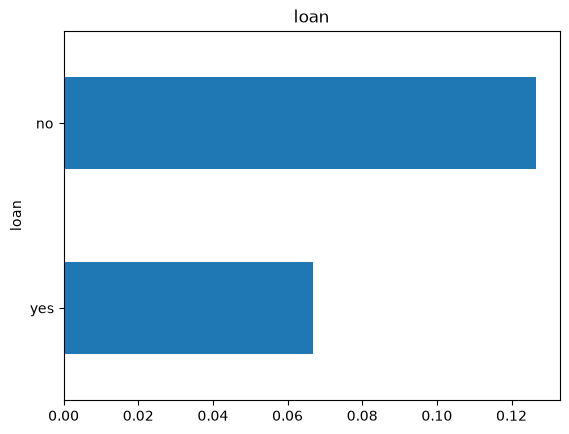

,rate,n
contact,,
cellular,0.149189,29285
telephone,0.134205,2906
NaN,0.040707,13020


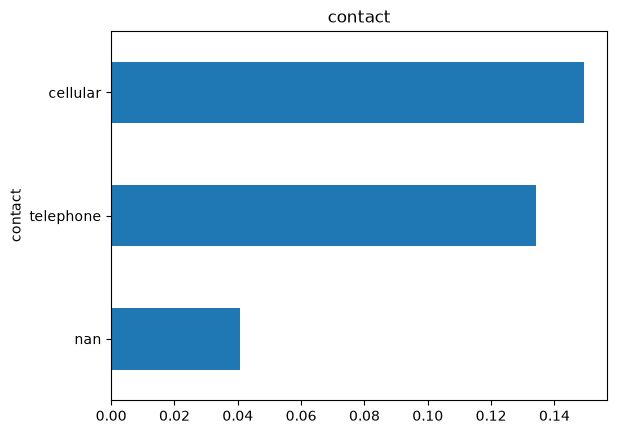

,rate,n
month,,
mar,0.519916,477
dec,0.467290,214
sep,0.464594,579
oct,0.437669,738
apr,0.196794,2932
feb,0.166478,2649
aug,0.110133,6247
jun,0.102228,5341
nov,0.101511,3970


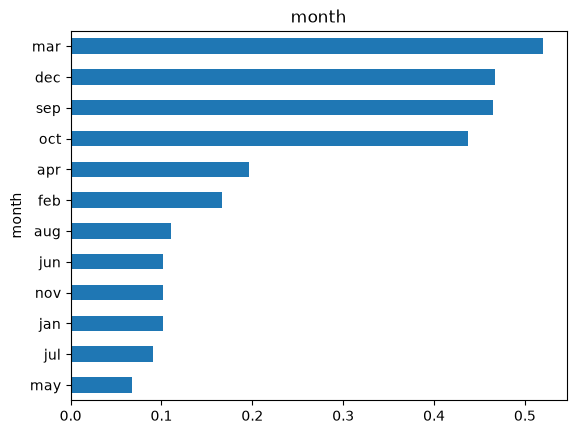

,rate,n
poutcome,,
success,0.647253,1511
other,0.166848,1840
failure,0.126097,4901
NaN,0.091615,36959


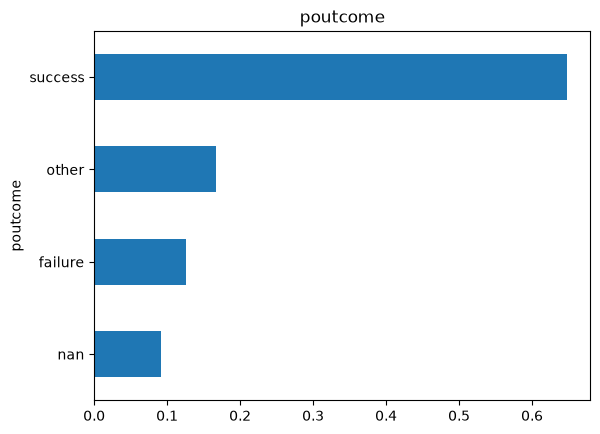

In [18]:
for c in cat_cols:
    t = df.groupby(c, dropna=False)["target"].agg(rate="mean", n="size").sort_values("rate")
    display(t.sort_values("rate", ascending=False))
    t["rate"].plot.barh(title=c); plt.show()

En las gráficas se revisa la relación de las variables categóricas y qué tanto cambia la tasa de suscripción entre cada categoría.

Siguientes pasos: convertir colummas de "yes/no" a binarias y hacer encoding.

### 2.5 Comparando numéricas con el target

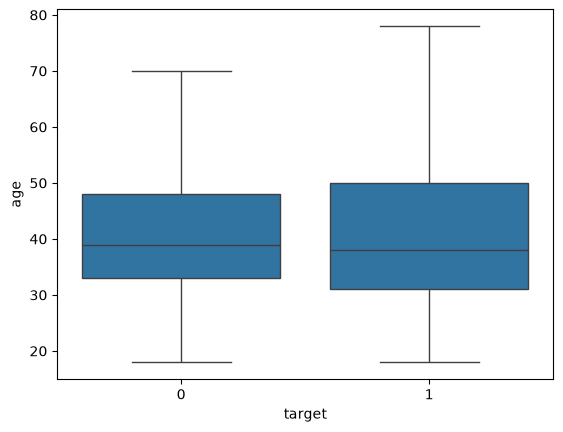

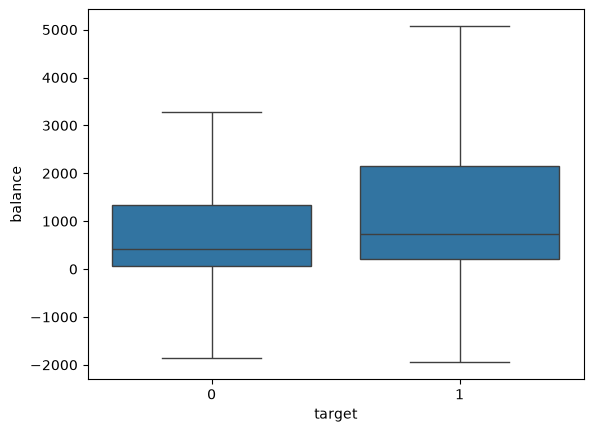

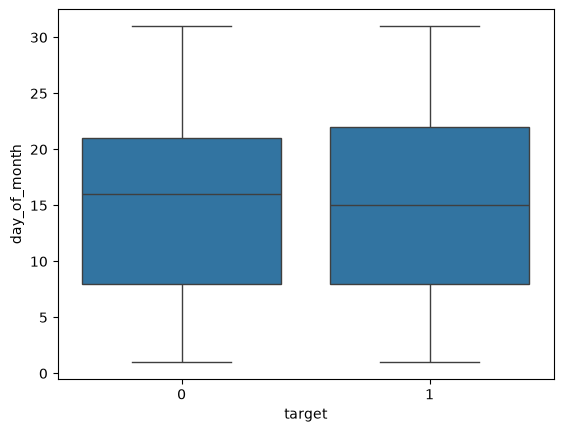

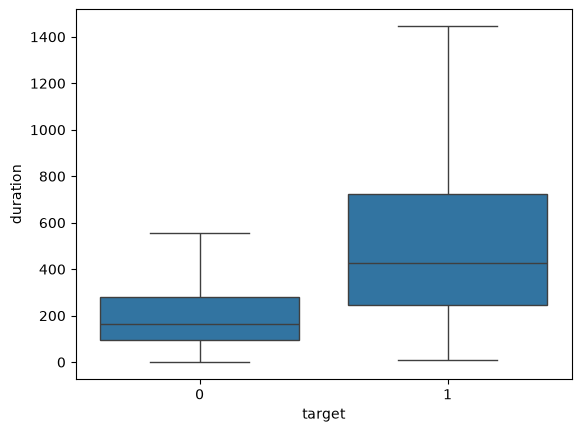

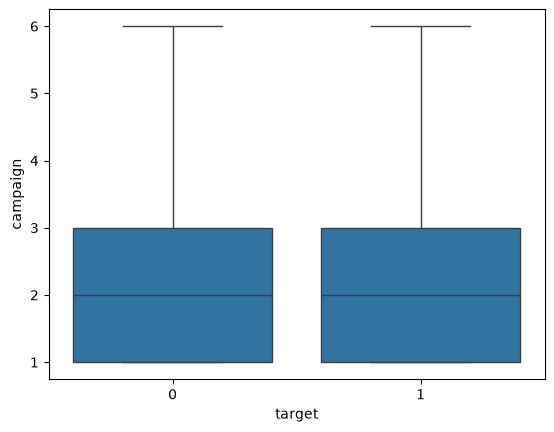

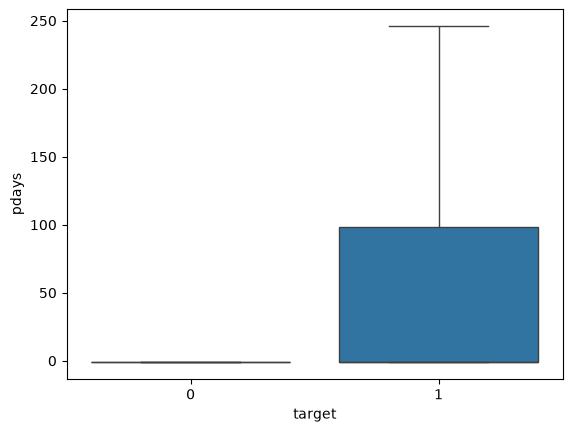

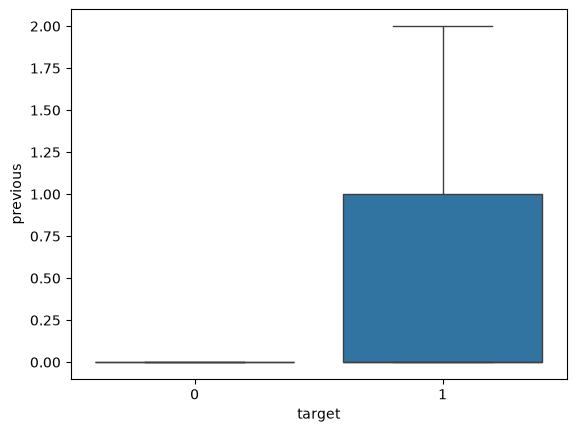

In [19]:
for c in num_cols:
    sns.boxplot(data=df, x="target", y=c, showfliers=False); plt.show()

Estas gráficas de *boxplot* muestran las relaciones entre las numéricas, separadas por el `target`

### 2.6 Correlaciones

<Axes: >

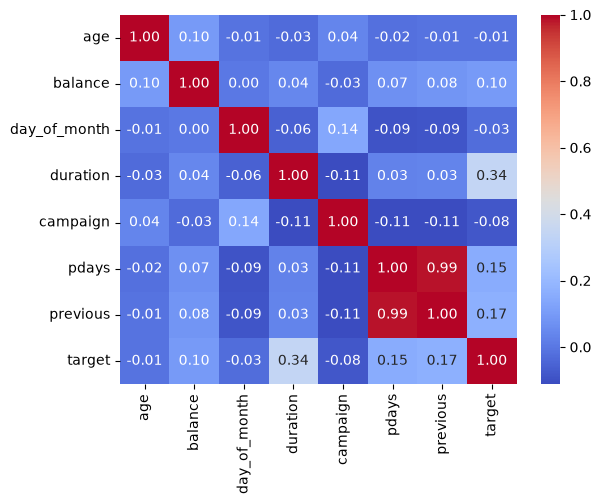

In [20]:
sns.heatmap(df[num_cols + ["target"]].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm")

`pdays` y `previous` están altamente correlacionadas (0.99), lo cual hace necesario crear un nuevo atributo `previously_contacted` mencionado en la sección 2.3.

### 2.7 Valores faltantes

In [21]:
df.isna().sum()

age                 0
job               288
marital             0
education        1857
default             0
balance             0
housing             0
loan                0
contact         13020
day_of_month        0
month               0
duration            0
campaign            0
pdays               0
previous            0
poutcome        36959
target              0
dtype: int64

In [22]:
df.isna().mean().sort_values(ascending=False)
for c in ["job", "education", "contact", "poutcome"]:
    print(c, df.groupby(df[c].isna())["target"].mean().round(3).to_dict())
pd.crosstab(df["poutcome"].isna(), df["pdays"] == -1)

job {False: 0.117, True: 0.118}
education {False: 0.116, True: 0.136}
contact {False: 0.148, True: 0.041}
poutcome {False: 0.231, True: 0.092}


pdays,False,True
poutcome,,
False,8252,0
True,5,36954


Se hace tabulación cruzada entre `poutcome` y `pdays`. Esto se interpreta como: cuando no existe un contacto previo registrado (`pdays == -1 == True`) el valor de `poutcome` está faltante. Lo contrario también es cierto a excepción de 5 casos, donde sí existió una campaña previa pero faltó registrar `poutcome`.

Siguientes pasos:
- `poutcome`: Se debe imputar como una categoría adicional ("none")
- Los demás atributos con valores faltantes: `job`, `education` y `contact` se imputarán de manera similar: un valor "unknown".

#### 2.8 el impacto de `duration`

In [23]:
df.loc[df["duration"] == 0, "target"].value_counts()

target
0    3
Name: count, dtype: int64

Hay una relación importante entre `duration` y `target`. La duración de una llamada se registra después de haber hecho el primer contacto. Dicho de otra manera, en todos los casos donde la duración es de 0, target se registra como 0. Esto se le conoce como "target leakage".

Para evitar esto, se hará un drop de esta categoría.

## Paso 3: Limpiando los datos

**Previo: Buscar duplicados y nulos (Paso 2 se encargó de nulos)**

In [24]:
df.duplicated().sum()

np.int64(0)

#### 3.1 Drop de `duration`

In [25]:
df = df.drop(columns=["duration"])

#### 3.2 Convertimos categorías binarias a 0/1 (target ya fue convertida)

In [26]:
binary_cols = ["default", "housing", "loan"]
for col in binary_cols:
    df[col] = (df[col] == "yes").astype(int)

#### 3.3 Encargándonos de los valores faltantes

Como vimos en la sección anterior. Imputaremos "none" para `poutcome`, "unknown" para el resto.

In [27]:
df["poutcome"] = df["poutcome"].fillna("none")

In [28]:
other_cols = ["job", "education", "contact"]
df[other_cols] = df[other_cols].fillna("unknown")

#### 3.4 Creamos la nueva propiedad `previously_contacted`

In [29]:
df["previously_contacted"] = (df["pdays"] != -1).astype(int)
df = df.drop(columns=["pdays"])

#### 3.5 Train test split

In [30]:
X = df.drop(columns=["target"])
y = df["target"]

In [31]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

In [32]:
# Check class balance in train and test sets
print("Train target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTest target distribution:")
print(y_test.value_counts(normalize=True))

Train target distribution:
target
0    0.883018
1    0.116982
Name: proportion, dtype: float64

Test target distribution:
target
0    0.883003
1    0.116997
Name: proportion, dtype: float64


#### 3.6 Preparando el pipeline

In [33]:
# Log transform (signed)
# from sklearn.preprocessing import FunctionTransformer
# signed_log = FunctionTransformer(lambda x: np.sign(x) * np.log1p(np.abs(x)))

In [34]:
# Standard scaling
from sklearn.preprocessing import StandardScaler

In [35]:
# One-hot encoding
from sklearn.preprocessing import OneHotEncoder
ohe = OneHotEncoder(handle_unknown="ignore", drop="if_binary")

In [36]:
# Assemble
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PowerTransformer

preprocessing = ColumnTransformer([
    ("power", PowerTransformer(method="yeo-johnson"), ["balance", "campaign", "previous"]),
    ("just_scaled", StandardScaler(), ["age", "day_of_month"]),
    ("onehot", ohe, ["job", "marital", "education", "contact", "poutcome", "month"])
], remainder="passthrough")

#### 3.7 Reflexión de preprocesamiento

Se aplicaron los preprocesamientos necesarios en los datos, de modo que el modelo con el cuál realizaremos clasificación binaria (Regresión Logística) obtenga el mayor provecho de los datos y no se tope con ningún tipo de error.

## Paso 4: Entrenando modelo base y Regresión logística
La división de datos en entrenamiento y prueba se hizo en el paso anterior, para evitar cualquier tipo de data leakage.
A continuación mostraremos el modelo baseline (dummy) y modelo de regresión logística básico

#### 4.1 DummyClassifier

In [37]:
# Wrap everything up with baseline model
from sklearn.dummy import DummyClassifier
dummy_pipeline = Pipeline([
    ("preprocessing", preprocessing),
    ("model", DummyClassifier(strategy="most_frequent"))
])

In [38]:
# Fit only on training data
dummy_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['age','job','marital',...,'previous','poutcome','previously_contacted']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('power', ...), ('just_scaled', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pas

#### 4.2 LogisticRegression 

In [39]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression

logreg_pipeline = Pipeline([
    ("preprocessing", clone(preprocessing)),
    ("model", LogisticRegression(class_weight="balanced", max_iter=1000)),
])
logreg_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['age','job','marital',...,'previous','poutcome','previously_contacted']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('power', ...), ('just_scaled', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pas

## Paso 5: Evaluando los modelos
La métrica que utilizaremos para evaluar el desempeño de ambos modelos será Curva ROC. La razón por la que usaremos esa es que si utilizamos exactitud, daría resultados incorrectos, ya que el dummy puede tener una mejor exactitud que cualquier otro modelo que tengamos, dado que tenemos `target` desbalanceado.

Entre las que se muestran en el reporte, existen recall, f1-score y precisión. Además, imprimiremos el valor de la curva ROC.

#### 5.1 DummyClassifier

In [40]:
from sklearn.metrics import classification_report, roc_auc_score

y_pred = dummy_pipeline.predict(X_test)
y_proba = dummy_pipeline.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, zero_division=0))
print("ROC AUC:", roc_auc_score(y_test, y_proba))

              precision    recall  f1-score   support

           0       0.88      1.00      0.94      7985
           1       0.00      0.00      0.00      1058

    accuracy                           0.88      9043
   macro avg       0.44      0.50      0.47      9043
weighted avg       0.78      0.88      0.83      9043

ROC AUC: 0.5


ROC AUC dio como resultado 50%, pues la probabilidad es la misma para cada cliente, es básicamente adivinar cada vez (sí o no).

Tal como se esperaba, el accuracy resultó de 88%. Ya que siempre predice la clase mayoritaria (negativa), por consiguiente, otras métricas como f1 y recall para la clase positiva siempre es 0.

**Guardando métricas para el paso 6**

In [41]:
from sklearn.metrics import accuracy_score, f1_score, recall_score
def calculate_metrics(y_true, y_pred, y_proba):
    """Helper function to calculate metrics"""
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "recall_yes": recall_score(y_true, y_pred, pos_label=1),
        "f1_yes": f1_score(y_true, y_pred, pos_label=1),
        "roc_auc": roc_auc_score(y_true, y_proba),
    }

In [42]:
dummy_metrics = calculate_metrics(y_test, y_pred, y_proba)

#### 5.2 LogisticRegression

In [43]:
y_pred = logreg_pipeline.predict(X_test)
y_proba = logreg_pipeline.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, zero_division=0))
print("ROC AUC:", roc_auc_score(y_test, y_proba))

              precision    recall  f1-score   support

           0       0.94      0.78      0.85      7985
           1       0.28      0.64      0.39      1058

    accuracy                           0.76      9043
   macro avg       0.61      0.71      0.62      9043
weighted avg       0.86      0.76      0.80      9043

ROC AUC: 0.7727184595880981


ROC AUC tuvo un cambio significativo de 50% a ~77%. Este incremento comparado con el baseline es relevante ya que nos indica que el modelo no está simplemente adivinando.

Adicionalmente, la exactitud de este modelo resultó peor que el baseline. Sin embargo, las demás métricas son mucho más altas. Indicando que el modelo sí obtuvo algo de aprendizaje con base en el entrenamiento.

**Guardando métricas para el paso 6**

In [44]:
logreg_metrics = calculate_metrics(y_test, y_pred, y_proba)

## Paso 6: Registrando el experimento en MLFlow

#### 6.1. Configuraciones iniciales

In [45]:
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("bank-marketing")

<Experiment: artifact_location='/Users/alabradasoto/ml/my-first-mlflow-model/mlruns/1', creation_time=1791057640908, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1791057640908, lifecycle_stage='active', name='bank-marketing', tags={}, trace_location=None, workspace='default'>

Registramos nuestra base de datos y el nuevo experimento.

#### 6.2. Crear signature y ejemplo

In [46]:
from mlflow.models import infer_signature
signature = infer_signature(X_train, logreg_pipeline.predict(X_train))
dummy_signature = infer_signature(X_train, dummy_pipeline.predict(X_train))
input_example = X_train.head(5)

/Users/alabradasoto/ml/my-first-mlflow-model/.venv/lib/python3.14/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


#### 6.3. Registrando corrida para cada modelo

Se registrará cada corrida, pero únicamente LogReg se incluirá en el registry

In [47]:
with mlflow.start_run(run_name="logreg_baseline"):
    mlflow.log_params({
        "model": "LogisticRegression",
        "class_weight": "balanced",
        "test_size": 0.2,
        "random_state": 42,
        "dropped_features": "duration, pdays",
    })
    mlflow.log_metrics(logreg_metrics)
    mlflow.sklearn.log_model(
        sk_model=logreg_pipeline,
        name="model",
        signature=signature,
        input_example=input_example,
        registered_model_name="bank-marketing-logreg"
    )

Successfully registered model 'bank-marketing-logreg'.
Created version '1' of model 'bank-marketing-logreg'.


In [48]:
dummy_signature = infer_signature(X_train, dummy_pipeline.predict(X_train))

/Users/alabradasoto/ml/my-first-mlflow-model/.venv/lib/python3.14/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


In [49]:
with mlflow.start_run(run_name="dummy_baseline"):
    mlflow.set_tag("role", "reference")
    mlflow.log_params({
        "model": "DummyClassifier",
        "strategy": "most_frequent",
        "test_size": 0.2,
        "random_state": 42,
        "dropped_features": "duration, pdays",
    })
    mlflow.log_metrics(dummy_metrics)
    mlflow.sklearn.log_model(
        sk_model=dummy_pipeline,
        name="model",
        signature=dummy_signature,
        input_example=X_train.head(5),
    )

## Paso 7: Reflexión final

En particular el flujo realizado para esta actividad lo veo correcto, los pasos fueron los adecuados para registrar los modelos exitosamente. Sin embargo, se puede mejorar aplicando prácticas de MLOps, en específico, aprovecharía más a profundidad las funcionalidades de MLFlow, de modo que podamos versionar los modelos, y eso reproducirlo en un ambiente de cloud. Utilizaría git y github actions para automatizar este proceso. Hay más cosas que se podrían hacer que pienso que forman parte de los siguientes módulos del curso, como por ejemplo producir una API a raíz de estos modelos.

Del lado profesional, veo mucho valor en tener experiencia en actividades y ejercicios como estos, considero que mis previos conocimientos en DevOps se pueden extrapolar hacia el contexto de ML. Pues siempre se debe tener en mente de que la única constante en proyectos de software/IA es el cambio, y aquí no sólo cambia el código, sino también los datos y las condiciones del modelo.

## Anexo: Captura de MLFlow

![captura](mlflow.png "mlflow")

## Declaración de Uso de Inteligencia Artificial

Durante la elaboración del presente trabajo se utilizó Anthropic Claude (modelo Claude Opus 5.5 y Sonnet 5) como herramienta de apoyo en las siguientes tareas específicas:

- Generación de código de python basado en prompts.
- Apoyo y seguimiento del flujo de ML.

La responsabilidad final sobre el contenido recae en un servidor. 

Anthropic. (2026). Claude (Opus 5.5) [Modelo de lenguaje grande]. https://claude.ai/
Anthropic. (2026). Claude (Sonnet 5) [Modelo de lenguaje grande]. https://claude.ai/
